# What Not to do in Weight Initilization and problems with it?

In [ ]:
import numpy as np
import pandas as pd

from sklearn.datasets import make_circles

import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense, Input

import matplotlib.pyplot as plt

# Case 1 : Zero Initialization

C:\Users\Keval\AppData\Local\Temp\ipykernel_12356\1212319012.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


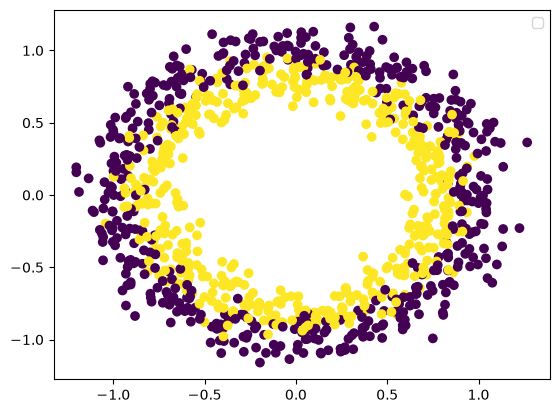

In [9]:
X, y = make_circles(n_samples=1000, noise=0.09, random_state=0)

plt.scatter(X[:,0], X[:, 1],c = y)
plt.legend()
plt.show()

## 1. ReLU/Tanh

In [10]:
model = Sequential([
    Input(shape = (2,)),
    Dense(2, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9 (36.00 B)

 Trainable params: 9 (36.00 B)

 Non-trainable params: 0 (0.00 B)

In [11]:
initial_weights = model.get_weights()
print(initial_weights)

[array([[ 0.22046733, -0.434915  ],
       [ 0.6938305 ,  0.18880963]], dtype=float32), array([0., 0.], dtype=float32), array([[ 0.30396914],
       [-1.039728  ]], dtype=float32), array([0.], dtype=float32)]


In [14]:
initial_weights[0] = np.zeros(shape = initial_weights[0].shape)
initial_weights[1] = np.zeros(shape = initial_weights[1].shape)
initial_weights[2] = np.zeros(shape = initial_weights[2].shape)
initial_weights[3] = np.zeros(shape = initial_weights[3].shape)

initial_weights

[array([[0., 0.],
        [0., 0.]]),
 array([0., 0.]),
 array([[0.],
        [0.]]),
 array([0.])]

In [15]:
model.set_weights(initial_weights)

model.compile(loss = 'binary_crossentropy', optimizer='Adam', metrics=['accuracy'])

history = model.fit(X, y, epochs=100, validation_split=0.2)

Epoch 1/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.4988 - loss: 0.6932 - val_accuracy: 0.5050 - val_loss: 0.6931
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4988 - loss: 0.6932 - val_accuracy: 0.5050 - val_loss: 0.6931
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4988 - loss: 0.6932 - val_accuracy: 0.5050 - val_loss: 0.6931
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4863 - loss: 0.6932 - val_accuracy: 0.5050 - val_loss: 0.6931
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4988 - loss: 0.6932 - val_accuracy: 0.5050 - val_loss: 0.6931
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4988 - loss: 0.6932 - val_accuracy: 0.5050 - val_loss: 0.6931
Epoch 7/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4712 - loss: 0.6933 - val_accuracy: 0.4950 - val_loss: 0.6932
Epoch 8/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5013 - loss: 0.6932 - val_accuracy: 0.4950 

In [16]:
model.get_weights()

[array([[0., 0.],
        [0., 0.]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[0.],
        [0.]], dtype=float32),
 array([0.00358838], dtype=float32)]

### As we can see that even after traning the Weights are still zero. So No traning is done.

## 2. Sigmoid

In [28]:
model = Sequential([
    Input(shape = (2,)),
    Dense(2, activation='sigmoid'),
    Dense(1, activation='sigmoid')
])

model.summary()

initial_weights = model.get_weights()
print(initial_weights)

initial_weights[0] = np.zeros(shape = initial_weights[0].shape)
initial_weights[1] = np.zeros(shape = initial_weights[1].shape)
initial_weights[2] = np.zeros(shape = initial_weights[2].shape)
initial_weights[3] = np.zeros(shape = initial_weights[3].shape)

model.set_weights(initial_weights)

model.compile(loss = 'binary_crossentropy', optimizer='Adam', metrics=['accuracy'])

history = model.fit(X, y, epochs=100, validation_split=0.2, verbose=0)

model.get_weights()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9 (36.00 B)

 Trainable params: 9 (36.00 B)

 Non-trainable params: 0 (0.00 B)

[array([[ 0.20715082, -0.58716273],
       [-0.31880015,  0.552701  ]], dtype=float32), array([0., 0.], dtype=float32), array([[0.23327875],
       [0.20996511]], dtype=float32), array([0.], dtype=float32)]


[array([[0.03817702, 0.03817702],
        [0.12182502, 0.12182502]], dtype=float32),
 array([-0.23794529, -0.23794529], dtype=float32),
 array([[0.00530107],
        [0.00530107]], dtype=float32),
 array([0.00320309], dtype=float32)]

In [30]:
model.get_weights()[1]

array([-0.23794529, -0.23794529], dtype=float32)

### as we can see that the weights of 1st Hidden Layer are equal. so the 2 nodes in that layers is acting as a single neuron and makes the model linear. 
### let's see the decision boundry of the model. 

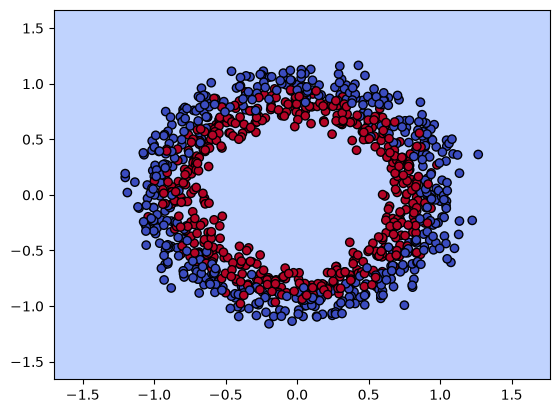

In [32]:
# build prediction grid
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 400),
    np.linspace(y_min, y_max, 400)
)

grid = np.c_[xx.ravel(), yy.ravel()]
Z = model.predict(grid, verbose=0).ravel()
Z = (Z > 0.5).astype(int)
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.55, cmap="coolwarm")
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k")
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.show()

### Model is predicting all the point same and working as a linear model.

# Case 2 : Non-Zero Constant Value

In [33]:
model = Sequential([
    Input(shape = (2,)),
    Dense(2, activation='sigmoid'),
    Dense(1, activation='sigmoid')
])

initial_weights = model.get_weights()

initial_weights[0] = np.ones(shape = initial_weights[0].shape)*0.5
initial_weights[1] = np.ones(shape = initial_weights[1].shape)*0.5
initial_weights[2] = np.ones(shape = initial_weights[2].shape)*0.5
initial_weights[3] = np.ones(shape = initial_weights[3].shape)*0.5

model.set_weights(initial_weights)

print(f"Before Training Weights : \n{model.get_weights()}")

model.compile(loss = 'binary_crossentropy', optimizer='Adam', metrics=['accuracy'])

history = model.fit(X, y, epochs=100, validation_split=0.2, verbose=0)

print(f"After Training Weights : \n{model.get_weights()}")

Before Training Weights : 
[array([[0.5, 0.5],
       [0.5, 0.5]], dtype=float32), array([0.5, 0.5], dtype=float32), array([[0.5],
       [0.5]], dtype=float32), array([0.5], dtype=float32)]
After Training Weights : 
[array([[0.5336862 , 0.5336862 ],
       [0.57626563, 0.57626563]], dtype=float32), array([0.19560882, 0.19560882], dtype=float32), array([[0.02261607],
       [0.02261607]], dtype=float32), array([-0.01622712], dtype=float32)]


### So non-zero Constant values also generate the same problem as Sigmoid with zero valued weights.

# Case 3 : Random Initialization In Deep Neural Network

### 1. Small Random Values

In [34]:
model = Sequential([
    Input(shape = (2,)),
    Dense(2, activation='tanh'),
    Dense(2, activation='tanh'),
    Dense(2, activation='tanh'),
    Dense(2, activation='tanh'),
    Dense(1, activation='sigmoid')
])

initial_weights = model.get_weights()

initial_weights[0] = np.random.randn(initial_weights[0].shape[0], initial_weights[0].shape[1]) * 0.01
initial_weights[1] = np.zeros(shape = initial_weights[1].shape)
initial_weights[2] = np.random.randn(initial_weights[2].shape[0], initial_weights[2].shape[1]) * 0.01
initial_weights[3] = np.zeros(shape = initial_weights[3].shape)
initial_weights[4] = np.random.randn(initial_weights[4].shape[0], initial_weights[4].shape[1]) * 0.01
initial_weights[5] = np.zeros(shape = initial_weights[5].shape)
initial_weights[6] = np.random.randn(initial_weights[6].shape[0], initial_weights[6].shape[1]) * 0.01
initial_weights[7] = np.zeros(shape = initial_weights[7].shape)
initial_weights[8] = np.random.randn(initial_weights[8].shape[0], initial_weights[8].shape[1]) * 0.01
initial_weights[9] = np.zeros(shape = initial_weights[9].shape)

model.set_weights(initial_weights)

print(f"Before Training Weights : \n{model.get_weights()}")

model.compile(loss = 'binary_crossentropy', optimizer='Adam', metrics=['accuracy'])

history = model.fit(X, y, epochs=100, validation_split=0.2, verbose=0)

print(f"After Training Weights : \n{model.get_weights()}")

Before Training Weights : 
[array([[ 0.00801897, -0.01287528],
       [-0.01070357,  0.00568523]], dtype=float32), array([0., 0.], dtype=float32), array([[ 0.01463295,  0.01478874],
       [-0.00645561,  0.00361593]], dtype=float32), array([0., 0.], dtype=float32), array([[0.01523841, 0.00089516],
       [0.00850955, 0.00405808]], dtype=float32), array([0., 0.], dtype=float32), array([[ 0.0116052 , -0.01460607],
       [ 0.00061231, -0.00483659]], dtype=float32), array([0., 0.], dtype=float32), array([[-0.00245087],
       [ 0.01574891]], dtype=float32), array([0.], dtype=float32)]
After Training Weights : 
[array([[ 0.007916  , -0.01284557],
       [-0.01075947,  0.00571006]], dtype=float32), array([-6.455978e-05,  8.091080e-06], dtype=float32), array([[ 0.01462838,  0.01477508],
       [-0.0064068 ,  0.00363657]], dtype=float32), array([-0.00166467, -0.00161732], dtype=float32), array([[0.01168992, 0.00294888],
       [0.00856235, 0.00217331]], dtype=float32), array([ 0.00062357, -0.

### There is barely any changes in the Weights. so this is same as Vanishing Gradient Problem for Tanh and Sigmoid.

### For ReLU - Convergece will be very slow at more than thousands epochs.

## 2. For Large Random Values 
- `tanh/Sigmoid` - get Saturated means most of the output of Activation Function will be either maximum or minimum of the function.
- `ReLU` -   Since it allows the numbers to be as big as possible in the positve region the gradient will also be large numbers because of that we get the unstable gradient.